# Canny Edge Detection — Demo visual y aplicaciones

Demostración interactiva de cómo el **parámetro $\sigma$** y la **remoción de ruido** afectan la detección de bordes con Canny.

## ¿Qué hace cada parámetro?

| Parámetro | Efecto |
|---|---|
| **σ (suavizado)** | Pequeño → detalles finos; Grande → solo estructuras grandes |
| **high_ratio** | Umbrales altos → solo bordes de alto contraste |
| **Ruido** | La remoción de ruido es **crítica**: sin ella, Canny marca el ruido como bordes |

## Setup

In [1]:
# Importar librerías necesarias
import os, cv2, numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import data, color, img_as_ubyte

# Configurar resolución de gráficas y semilla para reproducibilidad
plt.rcParams["figure.dpi"] = 90
np.random.seed(42)

## 1. Cargar imagen

Se busca en una ruta definida; si no existe, se usa una imagen de ejemplo.

In [ ]:
def load_test_image(path_candidates):
    # Buscar imagen en varias rutas; usar astronaut() si no existe.
    for p in path_candidates:
        if os.path.exists(p):
            bgr = cv2.imread(p)
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)        # Convertir BGR → RGB
            gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)      # Convertir a escala de grises
            # Recortar columna izquierda (artefacto brillante del archivo original)
            if gray[:, 0].mean() > 5 * (gray[:, 1].mean() + 1):
                rgb, gray = rgb[:, 1:], gray[:, 1:]
            return rgb, gray
    # Si no encuentra archivo, usar imagen de ejemplo
    rgb = data.astronaut()
    return rgb, img_as_ubyte(color.rgb2gray(rgb))

# Cargar imagen y mostrar información básica
img_rgb, img_gray = load_test_image(["./data/image.jpg"])
print(f"Imagen: {img_gray.shape}, intensidad media: {img_gray.mean():.1f}")

Imagen: (528, 975), intensidad media: 4.8


## 2. Pipeline de Canny

Pasos del algoritmo:
1. **Remoción de ruido** → filtro Gaussiano con $\sigma$
2. **Gradiente** → Sobel
3. **Adelgazamiento** → no-máximos
4. **Umbrales dobles** → píxeles fuertes/débiles
5. **Histéresis** → conectar píxeles débiles con fuertes

In [3]:
# ============================================
# Constantes para la histéresis
# ============================================
WEAK, STRONG = 25, 255  # Valores de píxeles débiles y fuertes

# ============================================
# PASO 1: REMOCIÓN DE RUIDO (Gaussiano)
# ============================================
def gaussian_kernel(size, sigma):
    # Crear un kernel Gaussiano 2D normalizado (suma = 1)
    k = int(size) // 2
    x, y = np.mgrid[-k:k + 1, -k:k + 1]
    # Fórmula Gaussiana 2D: exp(-(x²+y²)/(2σ²)) / (2πσ²)
    g = np.exp(-(x**2 + y**2) / (2.0 * sigma**2)) / (2.0 * np.pi * sigma**2)
    return g / g.sum()  # Normalizar para que suma=1 (no cambia brillo medio)

def gaussian_blur(img, sigma):
    # Aplicar filtro Gaussiano con σ. Si sigma≤0, devuelve imagen sin modificar.
    if sigma <= 0:
        return img.astype(np.float64)
    # Tamaño del kernel: captura ~99% de la masa Gaussiana en el rango ±3σ
    ks = 2 * int(np.ceil(3 * sigma)) + 1
    return cv2.filter2D(img.astype(np.float64), -1, gaussian_kernel(ks, sigma), 
                        borderType=cv2.BORDER_REFLECT)

# ============================================
# PASO 2: GRADIENTE (Kernels de Sobel)
# ============================================
def sobel_filters(img):
    # Calcular gradiente en x, y y magnitud usando los kernels de Sobel
    Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float64)    # Derivada en x
    Ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], np.float64)    # Derivada en y
    
    img = img.astype(np.float64)
    Ix = ndimage.convolve(img, Kx)           # Gradiente en x
    Iy = ndimage.convolve(img, Ky)           # Gradiente en y
    G = np.hypot(Ix, Iy)                     # Magnitud: |G| = sqrt(Ix² + Iy²)
    G = G / G.max() * 255 if G.max() > 0 else G  # Normalizar a [0, 255]
    theta = np.arctan2(Iy, Ix)               # Dirección: arctan(Iy/Ix)
    return G, theta

# ============================================
# PASO 3: ADELGAZAMIENTO (Non-Maximum Suppression)
# ============================================
def non_max_suppression(G, theta):
    # Mantener solo los máximos locales en la dirección del gradiente (bordes de 1 píxel)
    M, N = G.shape
    angle = np.rad2deg(theta) % 180          # Convertir ángulos radianes a grados [0, 180)
    P = np.pad(G, 1)                         # Rellenar bordes para evitar índices fuera de rango
    
    def nb(di, dj):
        # Helper: obtener píxel vecino desplazado (di, dj) para todos los píxeles
        return P[1 + di:1 + di + M, 1 + dj:1 + dj + N]
    
    q, r = np.zeros_like(G), np.zeros_like(G)
    # Clasificar ángulos en 4 direcciones principales (0°, 45°, 90°, 135°)
    masks = {
        (0, 1, 0, -1): (angle < 22.5) | (angle >= 157.5),     # 0° (bordes horizontales)
        (1, -1, -1, 1): (angle >= 22.5) & (angle < 67.5),     # 45°
        (1, 0, -1, 0): (angle >= 67.5) & (angle < 112.5),     # 90° (bordes verticales)
        (-1, -1, 1, 1): (angle >= 112.5) & (angle < 157.5),   # 135°
    }
    
    # Para cada dirección, comparar cada píxel con sus dos vecinos perpendiculares
    for (qi, qj, ri, rj), m in masks.items():
        q[m] = nb(qi, qj)[m]  # Vecino en dirección del gradiente
        r[m] = nb(ri, rj)[m]  # Vecino opuesto
    
    # Mantener solo si es máximo local (mayor que ambos vecinos)
    Z = np.where((G >= q) & (G >= r), G, 0.0)
    Z[[0, -1], :] = 0      # Anular bordes de la imagen
    Z[:, [0, -1]] = 0
    return Z

# ============================================
# PASO 4: DOBLE UMBRAL
# ============================================
def threshold(img, low_ratio=0.05, high_ratio=0.09):
    # Clasificar píxeles en 3 categorías: fuertes, débiles o descartados
    high = img.max() * high_ratio                    # Umbral fuerte (píxeles muy probables)
    low = high * low_ratio                           # Umbral débil (píxeles posibles)
    res = np.zeros(img.shape, np.uint8)
    res[img >= high] = STRONG                        # Píxeles fuertes (STRONG)
    res[(img >= low) & (img < high)] = WEAK         # Píxeles débiles (WEAK)
    # El resto queda en 0 (descartado)
    return res

# ============================================
# PASO 5: HISTÉRESIS (Conectividad)
# ============================================
def hysteresis(img):
    # Mantener píxeles débiles solo si están conectados (8-vecindad) a píxeles fuertes
    strong = img == STRONG
    candidates = strong | (img == WEAK)  # Píxeles a evaluar
    
    # Dilatar píxeles fuertes hasta converger, pero restringido a candidatos
    # Esto conecta píxeles débiles que toquen a píxeles fuertes
    edges = ndimage.binary_dilation(strong, structure=np.ones((3, 3), bool), 
                                    iterations=0, mask=candidates)
    return edges.astype(np.uint8) * STRONG

# ============================================
# FUNCIÓN PRINCIPAL: Pipeline Canny Completo
# ============================================
def canny_detector(img_gray, sigma=1.4, high_ratio=0.09):
    # Pipeline completo de Canny: 5 pasos en secuencia
    # sigma: desviación estándar del filtro Gaussiano (0-10)
    # high_ratio: umbral fuerte como fracción del máximo gradiente
    smooth = gaussian_blur(img_gray, sigma)       # Paso 1: Remoción de ruido
    G, theta = sobel_filters(smooth)              # Paso 2: Gradiente (Sobel)
    nms = non_max_suppression(G, theta)           # Paso 3: Adelgazamiento (NMS)
    thr = threshold(nms, high_ratio=high_ratio)   # Paso 4: Doble umbral
    return hysteresis(thr)                        # Paso 5: Histéresis

## 3. Efecto de σ: tamaño vs detalle

**σ pequeño** = muchos detalles + ruido | **σ grande** = solo estructura principal

> Modifica `SIGMAS` para probar otros valores.

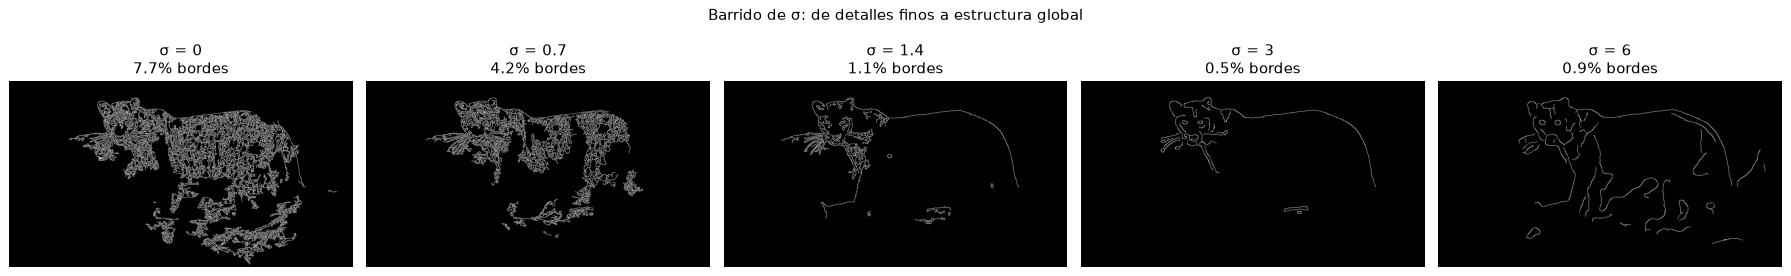

In [4]:
# Lista de valores sigma a probar
SIGMAS = [0, 0.7, 1.4, 3, 6]

# Aplicar detector de Canny con cada sigma
edges_list = [canny_detector(img_gray, s) for s in SIGMAS]
# Calcular porcentaje de píxeles clasificados como bordes
pct = [100 * (e > 0).mean() for e in edges_list]

# Visualizar resultados en fila
fig, axes = plt.subplots(1, len(SIGMAS), figsize=(4 * len(SIGMAS), 3.5))
for ax, s, e, p in zip(axes, SIGMAS, edges_list, pct):
    ax.imshow(e, cmap="gray")
    ax.set_title(f"σ = {s}\n{p:.1f}% bordes")
    ax.axis("off")
plt.suptitle("Barrido de σ: de detalles finos a estructura global", fontsize=12)
plt.tight_layout()
plt.show()

**Observaciones:**
- **σ = 0:** maraña de líneas (detalles, texturas, ruido del sensor).
- **σ = 0.7–1.4:** silueta clara del animal, detalles (bigotes).
- **σ = 3–6:** solo contornos gruesos, esquinas redondeadas.

## 4. Impacto de la remoción de ruido

¿Qué pasa si no suavizamos primero?

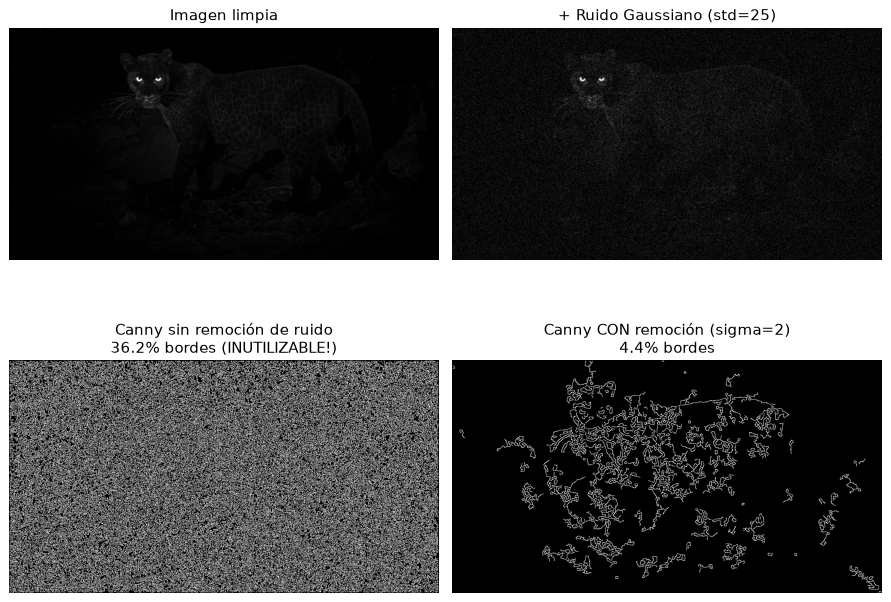

Imagen limpia: 1.1% bordes
Ruido + sin remoción: 36.2% bordes <- casi puro ruido
Ruido + con remoción (sigma=2): 4.4% bordes <- recupera silueta


In [5]:
# Generar versión ruidosa: agregar ruido Gaussiano (std=25)
img_noisy = img_gray.astype(float) + np.random.normal(0, 25, img_gray.shape)
img_noisy = np.clip(img_noisy, 0, 255).astype(np.uint8)  # Llevar a rango [0, 255]

# Aplicar Canny sin remoción de ruido (sigma=0)
edges_noisy_no_denoise = canny_detector(img_noisy, sigma=0)
# Aplicar Canny con remoción de ruido (sigma=2)
edges_noisy_with_denoise = canny_detector(img_noisy, sigma=2)
# Referencia: Canny en imagen limpia
edges_clean_ref = canny_detector(img_gray, sigma=1.4)

# Visualizar comparación en 2×2
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Superior izquierda: imagen limpia original
axes[0, 0].imshow(img_gray, cmap="gray")
axes[0, 0].set_title("Imagen limpia")
axes[0, 0].axis("off")

# Superior derecha: imagen con ruido agregado
axes[0, 1].imshow(img_noisy, cmap="gray")
axes[0, 1].set_title("+ Ruido Gaussiano (std=25)")
axes[0, 1].axis("off")

# Inferior izquierda: Canny sin remoción (resultado horrible!)
axes[1, 0].imshow(edges_noisy_no_denoise, cmap="gray")
pct_no = 100 * (edges_noisy_no_denoise > 0).mean()
axes[1, 0].set_title(f"Canny sin remoción de ruido\n{pct_no:.1f}% bordes (INUTILIZABLE!)")
axes[1, 0].axis("off")

# Inferior derecha: Canny con remoción (resultado mucho mejor)
axes[1, 1].imshow(edges_noisy_with_denoise, cmap="gray")
pct_yes = 100 * (edges_noisy_with_denoise > 0).mean()
axes[1, 1].set_title(f"Canny CON remoción (sigma=2)\n{pct_yes:.1f}% bordes")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

# Mostrar estadísticas
print(f"Imagen limpia: {100 * (edges_clean_ref > 0).mean():.1f}% bordes")
print(f"Ruido + sin remoción: {pct_no:.1f}% bordes <- casi puro ruido")
print(f"Ruido + con remoción (sigma=2): {pct_yes:.1f}% bordes <- recupera silueta")

**Conclusión:** Sin remoción de ruido, ~36 % de la imagen se marca como borde (es decir, el ruido). Con σ = 2 se recupera la silueta real (~1 % bordes).

## 5. Detectar estructuras de diferentes escalas

Cada imagen tiene características en distintos tamaños. σ controla a cuál "escala" se enfoca Canny.

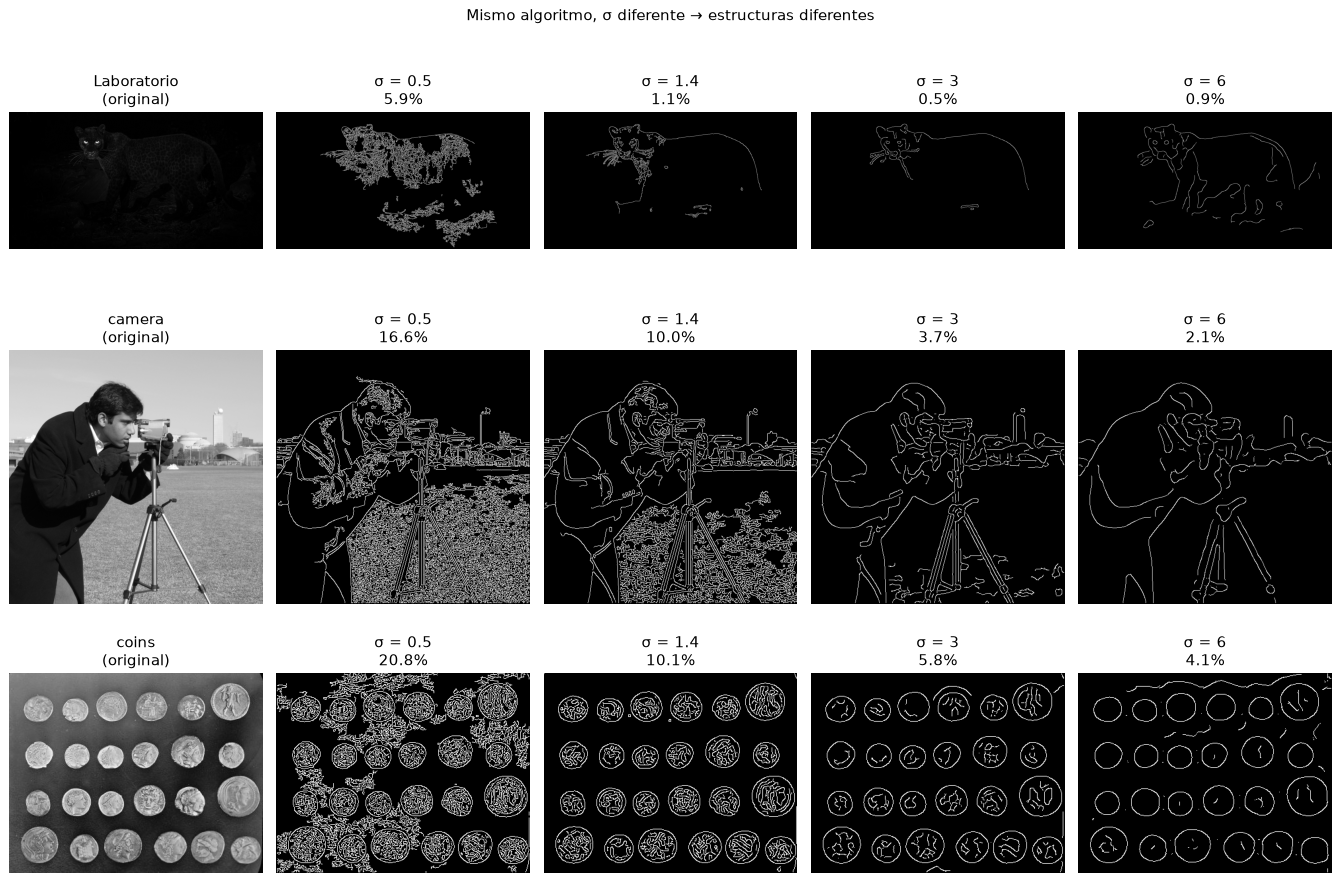

In [6]:
# Definir diccionario de imágenes de prueba
test_images = {
    "Laboratorio": img_gray,
    "camera": data.camera(),
    "coins": data.coins(),
}

# Valores de sigma a comparar
sigmas_demo = [0.5, 1.4, 3, 6]
n = len(test_images)

# Crear cuadrícula: filas = imágenes, columnas = original + sigma's
fig, axes = plt.subplots(n, 5, figsize=(15, 3.5 * n))
if n == 1:
    axes = axes.reshape(1, -1)

# Iterar sobre cada imagen de prueba
for row, (name, img) in enumerate(test_images.items()):
    # Columna 0: mostrar imagen original
    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title(f"{name}\n(original)")
    axes[row, 0].axis("off")
    
    # Columnas 1-4: aplicar Canny con distintos sigma
    for col, s in enumerate(sigmas_demo, 1):
        e = canny_detector(img, sigma=s)
        axes[row, col].imshow(e, cmap="gray")
        pct = 100 * (e > 0).mean()
        axes[row, col].set_title(f"σ = {s}\n{pct:.1f}%")
        axes[row, col].axis("off")

plt.suptitle("Mismo algoritmo, σ diferente → estructuras diferentes", fontsize=12)
plt.tight_layout()
plt.show()

- **Laboratorio:** σ=0.5 captura texturas; σ=1.4 la silueta; σ≥3 solo el lomo.
- **camera:** σ=0.5 marca ropa y fondo; σ=1.4 silueta clara; σ=6 solo contorno.
- **coins:** σ=1.4 detecta monedas individuales; σ=6 las monedas próximas se fusionan.

## 6. Ruido sal-y-pimienta: Gaussiano vs Mediana

Tipos distintos de ruido piden filtros distintos.

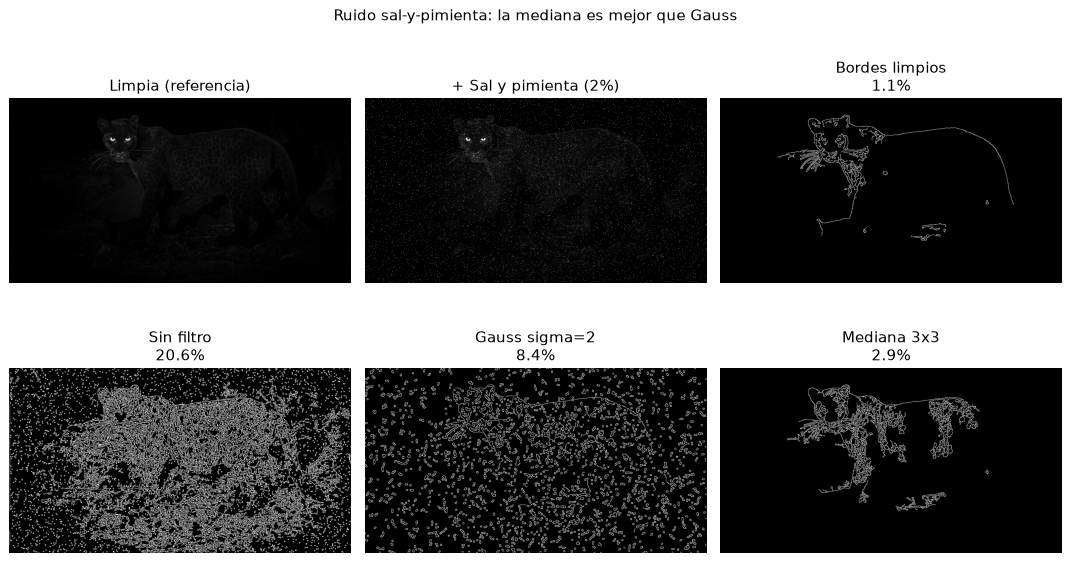

In [7]:
# Generar imagen con ruido sal-y-pimienta (puntos negros y blancos aleatorios)
img_sp = img_gray.copy()
mask = np.random.rand(*img_gray.shape) < 0.02  # 2% de píxeles afectados
img_sp[mask & (np.random.rand(*img_gray.shape) < 0.5)] = 0      # Sal (negro)
img_sp[mask & (np.random.rand(*img_gray.shape) >= 0.5)] = 255   # Pimienta (blanco)

# Aplicar distintos enfoques
edges_sp_no_filt = canny_detector(img_sp, sigma=0)              # Sin filtro
edges_sp_gauss = canny_detector(img_sp, sigma=2)                # Gauss sigma=2
img_sp_med = cv2.medianBlur(img_sp, 3)                          # Mediana 3x3 primero
edges_sp_med = canny_detector(img_sp_med, sigma=0.5)            # Luego Canny
edges_clean_ref = canny_detector(img_gray, sigma=1.4)           # Referencia (limpia)

# Visualizar en grid 2x3
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

# Fila superior
axes[0, 0].imshow(img_gray, cmap="gray")
axes[0, 0].set_title("Limpia (referencia)")
axes[0, 0].axis("off")

axes[0, 1].imshow(img_sp, cmap="gray")
axes[0, 1].set_title("+ Sal y pimienta (2%)")
axes[0, 1].axis("off")

axes[0, 2].imshow(edges_clean_ref, cmap="gray")
pct_ref = 100 * (edges_clean_ref > 0).mean()
axes[0, 2].set_title(f"Bordes limpios\n{pct_ref:.1f}%")
axes[0, 2].axis("off")

# Fila inferior: tres formas de tratar la imagen con ruido
axes[1, 0].imshow(edges_sp_no_filt, cmap="gray")
pct_no = 100 * (edges_sp_no_filt > 0).mean()
axes[1, 0].set_title(f"Sin filtro\n{pct_no:.1f}%")
axes[1, 0].axis("off")

axes[1, 1].imshow(edges_sp_gauss, cmap="gray")
pct_g = 100 * (edges_sp_gauss > 0).mean()
axes[1, 1].set_title(f"Gauss sigma=2\n{pct_g:.1f}%")
axes[1, 1].axis("off")

axes[1, 2].imshow(edges_sp_med, cmap="gray")
pct_m = 100 * (edges_sp_med > 0).mean()
axes[1, 2].set_title(f"Mediana 3x3\n{pct_m:.1f}%")
axes[1, 2].axis("off")

plt.suptitle("Ruido sal-y-pimienta: la mediana es mejor que Gauss", fontsize=12)
plt.tight_layout()
plt.show()

La **mediana** elimina puntos aislados sin difuminar bordes. El **Gaussiano** esparce los puntos en manchas que siguen generando bordes falsos.

## 7. Función reutilizable: `canny_detector`

Parámetros ajustables para aplicar a cualquier imagen.

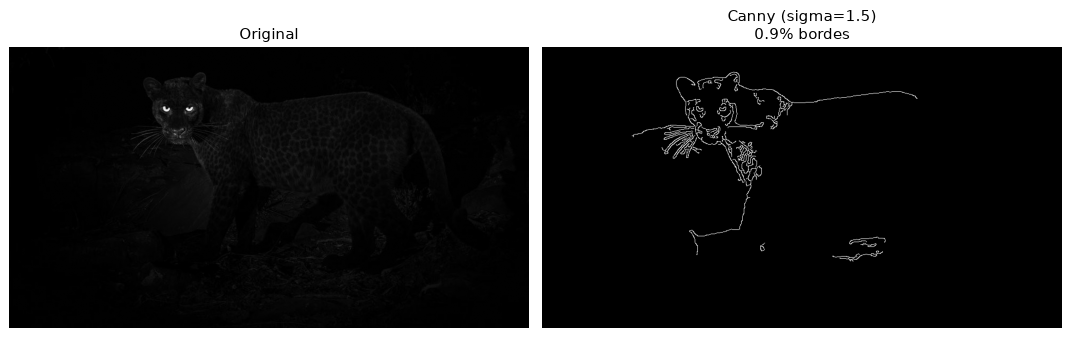

In [8]:
def canny_detector_full(image, sigma=1.4, high_ratio=0.09, denoise=True):
    # Detector de bordes Canny - versión con manejo flexible de entrada
    # 
    # Parameters:
    # -----------
    # image: ruta (str) o np.ndarray (gris o RGB)
    # sigma: suavizado Gaussiano (rango 0-10)
    # high_ratio: umbral fuerte como fracción de max(gradiente) [default 0.09]
    # denoise: bool, si False ignora sigma y usa sigma=0
    
    # Cargar imagen si es ruta (string)
    if isinstance(image, str):
        img = cv2.imread(image)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        # Si es arreglo numpy: convertir a escala de grises
        img = np.asarray(image)
        if img.ndim == 3:
            # RGB o RGBA → gris
            gray = color.rgb2gray(img) if img.shape[2] == 3 else cv2.cvtColor(img, cv2.COLOR_BGRA2GRAY)
        else:
            gray = img
        # Convertir a uint8 si está en otro formato
        gray = img_as_ubyte(gray) if gray.max() <= 1 else gray.astype(np.uint8)
    
    # Aplicar Canny con sigma (o sigma=0 si denoise=False)
    return canny_detector(gray, sigma=sigma if denoise else 0, high_ratio=high_ratio)

# Ejemplo: aplicar a la imagen del laboratorio
edges = canny_detector_full(img_gray, sigma=1.5, high_ratio=0.10)

# Visualizar lado a lado: original y bordes detectados
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.imshow(img_gray, cmap="gray")
ax1.set_title("Original")
ax1.axis("off")
ax2.imshow(edges, cmap="gray")
ax2.set_title(f"Canny (sigma=1.5)\n{100 * (edges > 0).mean():.1f}% bordes")
ax2.axis("off")
plt.tight_layout()
plt.show()

## Guía rápida para elegir σ

| Objetivo | σ recomendado | Por qué |
|---|---|---|
| Detectar **todos** los detalles | 0.5–1 | Captura texturas y ruido |
| Silueta clara (uso típico) | 1–2 | Balance detalle-ruido |
| Solo **estructuras grandes** | 3–5 | Ignora detalles finos |
| Imagen **muy ruidosa** | 3–6 | Más suavizado = menos falsos |

**NOTA:** σ pequeño para imágenes limpias; σ grande para imágenes ruidosas.

## Referencias en el código

- `canny_detector(img, sigma, high_ratio)` → función principal.
- `gaussian_blur(img, sigma)` → remoción de ruido.
- `sobel_filters(img)` → gradientes.
- `non_max_suppression(G, theta)` → adelgazamiento.
- `threshold(img, high_ratio)` → umbrales.
- `hysteresis(img)` → conectar píxeles débiles.